# Capstone – Fake news detector
## Notebook 2 – Baseline: TF-IDF + logistic regression

**Goal:** build a first classifier (Lab 4.2: TF-IDF + logistic regression), evaluate it on a held-out test set, and check how much of its score comes from the **source clues** found in notebook 1.

Plan:
1. Load the data and apply the decisions of notebook 1 (remove empty texts and duplicates).
2. Preprocess the text twice: **raw** (clues kept) and **clean** (clues removed with `remove_leaks`).
3. Experiment 1 – raw vs clean, same model, scored on the validation set.
4. Experiment 2 – three linear models of Lab 4.2 on the clean text: logistic regression, linear SVM, Naive Bayes.
5. Final evaluation **once** on the test set: accuracy, F1-score, confusion matrix.
6. Most predictive words, error analysis, save the model for the app.

Vocabulary:
- **TF-IDF** (Term Frequency – Inverse Document Frequency): weight of a word = frequent in this article × rare in the corpus.
- **SVM** (Support Vector Machine): linear model that looks for the boundary with the largest margin between classes.
- **F1-score**: harmonic mean of precision and recall; *macro* = average of the F1 of the two classes.

Grading criterion covered: **NLP pipeline (6 pts)** – *preprocessing adapted to the data, sensible choice of representation and model, evaluation with a metric, error analysis*.

## Setup

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

sys.path.append("..")  # to import our own code from src/
from src.preprocessing import build_input, remove_leaks

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 150)
RANDOM_STATE = 42
LABELS = {0: "fake", 1: "real"}

# Part 1 – Load and clean the data

Same loading as notebook 1. Notebook 1 found only 2 empty texts, no duplicated text and no overlap between splits, so we keep the official splits: **train** to fit the models, **validation** to compare them, **test** only once at the end.

In [2]:
DATA_DIR = Path("../data")
frames = []
for split_name in ["train", "validation", "test"]:
    part = pd.read_parquet(DATA_DIR / f"{split_name}-00000-of-00001.parquet")
    part["split"] = split_name
    frames.append(part)
df = pd.concat(frames, ignore_index=True).drop(columns=["Unnamed: 0"], errors="ignore")

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")
df = df[df["text"].str.strip() != ""]
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(df.groupby("split")["label"].agg(["count", "mean"]).rename(columns={"mean": "share of real"}).round(3))

            count  share of real
split                           
test         8117          0.534
train       24352          0.542
validation   8116          0.541


# Part 2 – Preprocessing

The functions are in `src/preprocessing.py` so the Streamlit app uses **exactly the same** preprocessing:

- `remove_leaks`: removes the source clues found in notebook 1 with regular expressions – the `CITY (Reuters) -` dateline and every other mention of *Reuters*, *Featured image / image via* credits, URLs, embedded tweet links (`pic.twitter.com/...`), Twitter handles, `[Video]` / `(IMAGE)` tags, titles starting with `WATCH:`.
- `preprocess_advanced` (Lab 4.2): lowercase, letters only, tokenization, stop words removed, lemmatization, words of 3+ letters.
- `build_input`: title + text → (optional `remove_leaks`) → `preprocess_advanced`.

The model input is **title + text**: the title carries information (notebook 1: fake titles are longer and more sensational).

In [3]:
example = df[df["label"] == 1].iloc[0]
print("ORIGINAL :", example["text"][:200], "\n")
print("NO LEAKS :", remove_leaks(example["text"])[:200], "\n")
print("MODEL INPUT (clean):", build_input(example["title"], example["text"])[:200])

ORIGINAL : MOSCOW (Reuters) - Russia on Wednesday warned Iraq and the Kurds against taking any steps that might destabilize the Middle East after a Kurdish independence referendum, encouraging both sides to hold 

NO LEAKS :  Russia on Wednesday warned Iraq and the Kurds against taking any steps that might destabilize the Middle East after a Kurdish independence referendum, encouraging both sides to hold talks to find a s 

MODEL INPUT (clean): russia warns iraq kurd destabilize middle east kurdish vote russia wednesday warned iraq kurd taking step might destabilize middle east kurdish independence referendum encouraging side hold talk find 


In [4]:
# About 2-4 minutes: tokenization and lemmatization of ~40k articles, done twice
start = time.time()
df["input_raw"] = [build_input(t, x, clean_leaks=False) for t, x in zip(df["title"], df["text"])]
df["input_clean"] = [build_input(t, x, clean_leaks=True) for t, x in zip(df["title"], df["text"])]
print(f"Preprocessing done in {time.time() - start:.0f} s")

train, val, test = (df[df["split"] == s] for s in ["train", "validation", "test"])
y_train, y_val, y_test = train["label"], val["label"], test["label"]

Preprocessing done in 88 s


# Part 3 – Experiment 1: raw text vs clean text

Same model on both inputs: TF-IDF on words and bigrams (pairs of consecutive words) + logistic regression. If the score drops a lot after cleaning, the raw model was mostly recognising the **source** instead of the content.

In [5]:
def make_model(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9,
                                  max_features=50000, sublinear_tf=True)),
        ("clf", classifier),
    ])

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "F1 macro": f1_score(y_true, y_pred, average="macro")}

results = {}
for name, column in [("raw (clues kept)", "input_raw"), ("clean (clues removed)", "input_clean")]:
    model = make_model(LogisticRegression(max_iter=1000))
    model.fit(train[column], y_train)
    results[name] = scores(y_val, model.predict(val[column]))

pd.DataFrame(results).T.round(4)

,accuracy,F1 macro
raw (clues kept),0.9729,0.9727
clean (clues removed),0.9669,0.9666


**Interpretation:** with the clues kept, the model reaches 97.3% accuracy on the validation set; after removing them it still reaches 96.7%. The drop is small (−0.6 point), so the model does **not** rely only on *Reuters* and the other clues we removed. But this does not prove that it understands the content: the two sources still differ in **writing style** (agency vs blog), and TF-IDF captures this style through ordinary words (see Part 6). The clean score is the honest one: it is the score we report and the model we keep.

# Part 4 – Experiment 2: three linear models on the clean text

The three classifiers of Lab 4.2, with the same TF-IDF representation, compared on the validation set.

In [6]:
candidates = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
}
comparison = {}
for name, classifier in candidates.items():
    model = make_model(classifier)
    start = time.time()
    model.fit(train["input_clean"], y_train)
    comparison[name] = {**scores(y_val, model.predict(val["input_clean"])), "train time (s)": time.time() - start}

pd.DataFrame(comparison).T.round(4)

,accuracy,F1 macro,train time (s)
Logistic regression,0.9669,0.9666,11.0883
Linear SVM,0.9740,0.9738,10.7647
Naive Bayes,0.9354,0.9351,11.1774


**Choice:** we keep the **logistic regression**, even if the linear SVM is at the same level: it gives a **probability** (shown in the app as a confidence score) and its coefficients are easy to read (Part 6).

# Part 5 – Final evaluation on the test set

The test set has not been used for any choice so far, so this score is an honest estimate on articles of the same kind as the training data.

              precision    recall  f1-score   support

        fake     0.9610    0.9648    0.9629      3782
        real     0.9692    0.9659    0.9675      4335

    accuracy                         0.9654      8117
   macro avg     0.9651    0.9653    0.9652      8117
weighted avg     0.9654    0.9654    0.9654      8117



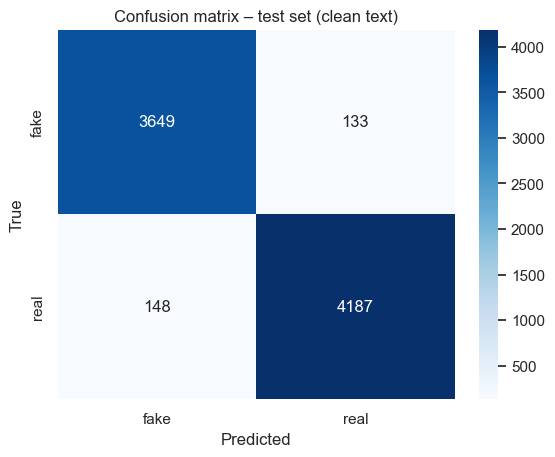

In [7]:
final_model = make_model(LogisticRegression(max_iter=1000))
final_model.fit(train["input_clean"], y_train)
y_pred = final_model.predict(test["input_clean"])

print(classification_report(y_test, y_pred, target_names=["fake", "real"], digits=4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["fake", "real"], yticklabels=["fake", "real"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix – test set (clean text)")
plt.show()

# Part 6 – Most predictive words

In a logistic regression, each word or bigram has a coefficient: positive pushes towards **real** (label 1), negative towards **fake** (label 0).

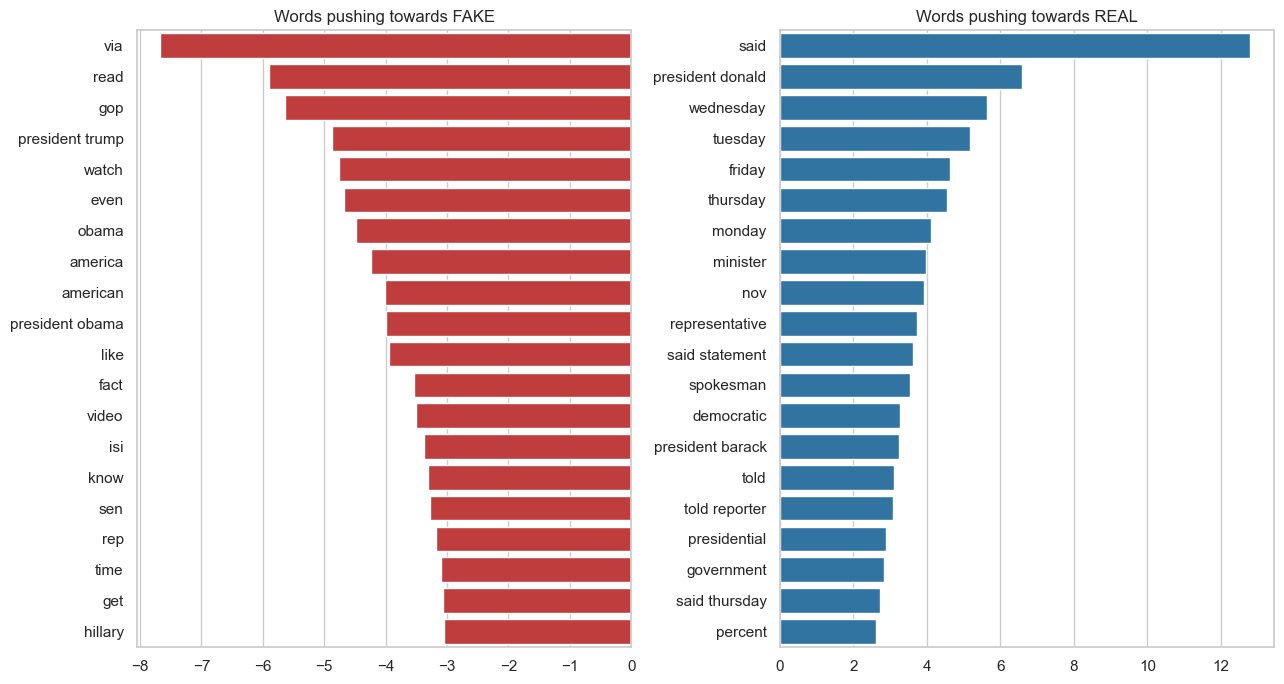

In [8]:
vocab = final_model.named_steps["tfidf"].get_feature_names_out()
coefs = final_model.named_steps["clf"].coef_[0]
order = np.argsort(coefs)

top_n = 20
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
sns.barplot(x=coefs[order[:top_n]], y=vocab[order[:top_n]], ax=axes[0], color="tab:red")
axes[0].set_title("Words pushing towards FAKE")
sns.barplot(x=coefs[order[::-1][:top_n]], y=vocab[order[::-1][:top_n]], ax=axes[1], color="tab:blue")
axes[1].set_title("Words pushing towards REAL")
plt.tight_layout()
plt.show()

**Interpretation:**
- Words pushing towards **real** are mostly about the **Reuters writing style**, not about facts: *said*, *said statement*, *told reporter*, *spokesman*, the days of the week (*wednesday*, *tuesday*... – agency articles always date events), *nov*, *percent*, formal titles (*president donald*, *president barack*, *minister*, *representative*).
- Words pushing towards **fake** are about the **blog / opinion style**: *via* (left from image and source credits), *read* (*"read more"*), *watch*, *video*, informal words (*like*, *even*, *know*, *get*, *thing*, *fact*), short forms (*gop*, *sen*, *rep*, *isi* from *ISIS*), and the way people are named (*president obama*, *hillary* alone).
- So the classifier learns mainly **"agency style vs blog style"**. This works very well on this dataset, but a fake article written in a neutral agency style, or a real article written in an informal style, will probably fool it. The test on recent articles (later notebook) will measure this.

# Part 7 – Error analysis

We look at the misclassified test articles, starting with the ones where the model was the most confident.

In [9]:
errors = test.copy()
errors["pred"] = y_pred
errors["proba_real"] = final_model.predict_proba(test["input_clean"])[:, 1]
errors = errors[errors["pred"] != errors["label"]].copy()
errors["confidence"] = np.where(errors["pred"] == 1, errors["proba_real"], 1 - errors["proba_real"])
errors["true"] = errors["label"].map(LABELS)
errors["predicted"] = errors["pred"].map(LABELS)
errors["text_start"] = errors["text"].str[:150]

print(f"{len(errors)} errors out of {len(test)} test articles")
print(errors["true"].value_counts().rename("errors by true class"))
errors.sort_values("confidence", ascending=False)[["title", "text_start", "true", "predicted", "confidence"]].head(10)

281 errors out of 8117 test articles
true
real    148
fake    133
Name: errors by true class, dtype: int64


,title,text_start,true,predicted,confidence
34157,reasons why you should apply for a job in the trump administration,usa created isis all european know about that now were all scared ndma \nlets just remember who enslaves usa which entity forced them to do so p...,real,fake,0.994876
40052,thoughts on steve bannon as white house chief strategist dailywirecom,shapiro eviscerates raucous protesters at university of wisconsin by hank berrien november \ndaily wire editorinchief ben shapiro spoke at the u...,real,fake,0.993151
36916,watch how i make my own bread at home with a bread machine,as feminism erodes down to its tattooed lesbian core we should stop and take a moment to wonder what the point of the third wave part of feminism ...,real,fake,0.983646
35253,comment on reasons why your diet sucks by the most important concepts the manosphere taught me,rejoice gentlemen the tears of liberals are flowing freely as donald trump has recently been announced president all of the hard work that weve co...,real,fake,0.972316
33743,quake near oklahoma oil hub causes substantial damage,russia china look to autonomous financial system \ntasscom \nrussia and china need to create an autonomous financial system which would be minima...,fake,real,0.968802
34418,is western civilization worth saving,with her hollywood and silver screen career options all but dried up former charmed actress and constantly nearnaked attentionseeker rose mcgowan ...,real,fake,0.965211
36099,donald trump rushed off stage in reno after possible assassination attempt,by now everyone has been reminded that the media is not infallible it is composed of very fallible human beings who make mistakes with the same re...,real,fake,0.964169
38024,women only hate female objectification when they can no longer profit from it,home be the change government corruption not just hillary entire obama administration exposed for using private email to avoid foia requests no...,real,fake,0.963192
39871,Text: Mitt Romney speech slamming Donald Trump,(Reuters) - The following is the full text of the speech delivered on Thursday by former Massachusetts Governor and 2012 Republican nominee for U....,real,fake,0.959505
32560,texas officer shot dead outside police hq,snowflake colbert didnt want to write jokes about trump winning by hank berrien november \nconversing with fellow daily show comic john oliver a...,real,fake,0.958418


In [10]:
# Are errors more frequent for short articles?
test_eval = test.assign(correct=(y_pred == y_test.to_numpy()), words=test["text"].str.split().str.len())
test_eval["length"] = pd.cut(test_eval["words"], bins=[0, 100, 300, 600, 100000],
                             labels=["< 100", "100-300", "300-600", "> 600"])
print((1 - test_eval.groupby("length", observed=True)["correct"].mean()).rename("error rate").round(4))

length
< 100      0.0276
100-300    0.0364
300-600    0.0313
> 600      0.0459
Name: error rate, dtype: float64


In [11]:
# Errors by sub-group. In notebook 1, 96% of the real articles came from Reuters.
# Who are the other 4%? Their text is often all lowercase, without punctuation (another source dataset).
group = np.where(test["label"] == 0, "fake",
                 np.where(test["text"].str.contains(r"\(Reuters\)"), "real – Reuters", "real – other source"))
by_group = pd.DataFrame({"group": group, "correct": y_pred == y_test.to_numpy()})
summary = by_group.groupby("group")["correct"].agg(articles="count", error_rate=lambda c: 1 - c.mean())
display(summary.round(4))

print("Examples of 'real – other source' articles:")
display(test[group == "real – other source"][["title", "text"]].head(5).apply(lambda c: c.str[:120]))

,articles,error_rate
group,,
fake,3782,0.0352
real – Reuters,4149,0.0082
real – other source,186,0.6129


Examples of 'real – other source' articles:


,title,text
32530,tom hayden from sds and viet cong to progressives for obama,search the left in power clinton to obama david horowitz explains how the democrats became a leftwing party in volume v
32560,texas officer shot dead outside police hq,snowflake colbert didnt want to write jokes about trump winning by hank berrien november \nconversing with fellow daily
32580,obamas doj hasnt approved warrant for fbi of new hillary emails,dems file complaint wdoj against fbi for investigating hillary \nits an obviously absurd move but considering that the
32653,dr duke and dr macdonald call for prosecution of hillary for treasonous support of isis,how they could steal the election from trump even if he is announced the winner next tuesday october at am \nhow they
32753,"Factbox: Trump on Twitter (Aug 25) - Republicans, John Kelly, Hurricane Harvey","The following statements were posted to the verified Twitter accounts of U.S. President Donald Trump, @realDonaldTrump a"


**Finding:** the "real – other source" articles are a small group (about 4% of the real class) coming from a different source dataset: lowercase text, titles that sometimes do not match the text, and content that often looks like partisan blogs. A large share of them is misclassified. They are probably **label noise** (articles labelled *real* that are not reliable news) – an honest limit of the dataset to mention in the presentation.

**What the errors have in common:**
- **Label noise** is the first cause: the small "real – other source" group (186 test articles, 2% of the test set) produces **114 of the 281 errors** (61% error rate vs 0.8% for Reuters articles). These articles are lowercase, without punctuation, sometimes with a title that does not match the text, and many come from partisan blogs: the model calls them *fake*, which is often defensible.
- **Fake articles that rewrite real news calmly** are predicted *real* (3.5% of fake articles are missed). Typically: a sensational title in CAPITALS (*"BOOM!"*, *"SLAMS"*, *"JUST IN TIME FOR RE-ELECTION…"*) followed by a body that paraphrases agency news in a neutral tone. The capitals are a strong fake clue in notebook 1, but `preprocess_simple` lowercases everything, so the model never sees them – an improvement idea.
- **Reuters articles that do not look like hard news** are predicted *fake* (only 34 of them): feature and human-interest stories (protests, rallies, a quarrel between Trump and Cruz, the *Hamilton* cast, culture and travel stories) and *Factbox* lists – they use the emotional, informal vocabulary of the fake class.
- **Length** has little effect: the error rate stays between 2.8% and 4.6%; very long articles (> 600 words) are slightly harder.

# Part 8 – Save the model for the app

The whole pipeline (TF-IDF + logistic regression) is saved in one file. The app loads it, applies `build_input` to the article typed by the user, and calls `predict_proba`.

In [12]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "baseline_tfidf_logreg.joblib"
joblib.dump(final_model, model_path, compress=3)
print(f"Saved: {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Check: reload and predict one test article
reloaded = joblib.load(model_path)
row = test.iloc[0]
proba = reloaded.predict_proba([build_input(row["title"], row["text"])])[0]
print(f"True: {LABELS[row['label']]} – predicted proba fake = {proba[0]:.2f}, real = {proba[1]:.2f}")

Saved: ../models/baseline_tfidf_logreg.joblib (1.0 MB)
True: fake – predicted proba fake = 0.87, real = 0.13


# Summary

1. **Raw vs clean:** the same TF-IDF + logistic regression model scores 97.3% accuracy on validation with the source clues and 96.7% without them (−0.6 point). The model does not depend only on *Reuters*, image credits or URLs, but it still uses the writing style of each source.
2. **Model comparison (validation, clean text):** linear SVM (Support Vector Machine) 97.4% > logistic regression 96.7% > Naive Bayes 93.5%. We keep the **logistic regression**: only 0.7 point below the SVM, but it gives a probability (confidence score in the app) and its coefficients explain each decision.
3. **Final test score** (8,117 articles never used before): **accuracy 96.5%, F1 macro 96.5%** (F1 fake 96.3%, F1 real 96.8%). 281 errors, balanced between the two classes (133 fake predicted real, 148 real predicted fake).
4. **Most predictive words:** mostly **style**, not content. *said*, days of the week, *spokesman*, *percent* → real (agency style); *via*, *read*, *watch*, *video*, *like*, *even*, *gop* → fake (blog style).
5. **Errors:** 41% of the errors come from 2% of the test set – "real" articles from another source that look like blogs (probable label noise). The other errors are fake articles with a sensational title but a neutral body (the model loses the capitals because the text is lowercased) and Reuters feature stories written in a more emotional style.
6. **Limits:**
   - The 96.5% is measured on articles **of the same sources and period** (2015-2017) as the training data; it will be lower on recent articles from other sources.
   - The model judges the **style** of an article, not whether its facts are true: it cannot check facts.
   - Some labels of the dataset are wrong, so part of the "errors" are in fact correct predictions.
   - English only, mostly US politics.

**Next notebook (3 – comparison):** sentence embeddings (Lab 3.2) + logistic regression, compared with this baseline on the same test set.